# APY Dataset — Exploratory Data Analysis (EDA)

## Objective

This notebook explores historical agricultural Area, Production, and Yield (APY) data to identify trends, distributions, regional differences, and data-quality concerns relevant to BharatCrop Intelligence.

### Analysis Plan
1. Understand the dataset's structure and coverage.
2. Examine crop, state, district, and season distributions.
3. Analyze missing measurements and quality flags.
4. Explore historical Area, Production, and Yield trends.
5. Compare individual crops and regions.
6. Investigate suspicious Yield values and potential outliers.

### Analysis Principles
- Keep aggregate crop categories separate from individual-crop comparisons.
- Do not interpret missing measurements as zero.
- Treat unusual values as investigation candidates, not automatic errors.
- Interpret trends in the context of data coverage and reporting limitations.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

project_root = Path.cwd().parent

input_path = (
    project_root
    / "data"
    / "processed"
    / "historical_food_grains_apy_long_2013-14_to_2024-25.csv"
)

apy_eda_df = pd.read_csv(input_path)

print("Input file exists:", input_path.exists())
print("Dataset shape:", apy_eda_df.shape)
print("Agricultural years:", sorted(apy_eda_df["Year"].unique()))
print("\nColumn data types:")
display(apy_eda_df.dtypes.to_frame("Data Type"))

print("\nFirst five records:")
display(apy_eda_df.head())

Input file exists: True
Dataset shape: (376272, 13)
Agricultural years: ['2013-14', '2014-15', '2015-16', '2016-17', '2017-18', '2018-19', '2019-20', '2020-21', '2021-22', '2022-23', '2023-24', '2024-25']

Column data types:


,Data Type
State,object
District,object
Crop,object
Season,object
Crop_Category,object
Year,object
Area,float64
Production,float64
Yield,float64
QC_AreaZero-ProductionPositive,bool



First five records:


,State,District,Crop,Season,Crop_Category,Year,Area,Production,Yield,QC_AreaZero-ProductionPositive,QC_AreaPositive-ProductionZero,QC_NegativeMeasurements,QC_PositiveYieldWithoutPositiveAreaProduction
0,Andaman And Nicobar Islands,Nicobars,Cereals,Kharif,Grouping — Verify Source Definition,2013-14,0.0,0.0,2377.0,False,False,False,True
1,Andaman And Nicobar Islands,Nicobars,Cereals,Rabi,Grouping — Verify Source Definition,2013-14,0.0,0.0,526.0,False,False,False,True
2,Andaman And Nicobar Islands,Nicobars,Cereals,Total,Grouping — Verify Source Definition,2013-14,0.0,0.0,923.0,False,False,False,True
3,Andaman And Nicobar Islands,Nicobars,Maize,Rabi,Individual Crop Candidate,2013-14,0.0,0.0,526.0,False,False,False,True
4,Andaman And Nicobar Islands,Nicobars,Maize,Total,Individual Crop Candidate,2013-14,0.0,0.0,526.0,False,False,False,True


In [2]:
# Summarize the coverage of the APY dataset.

coverage_summary = pd.DataFrame({
    "Unique Values": [
        apy_eda_df["State"].nunique(),
        apy_eda_df["District"].nunique(),
        apy_eda_df["Crop"].nunique(),
        apy_eda_df["Season"].nunique(),
        apy_eda_df["Year"].nunique(),
        apy_eda_df["Crop_Category"].nunique(),
    ],
    "Missing Values": [
        apy_eda_df["State"].isna().sum(),
        apy_eda_df["District"].isna().sum(),
        apy_eda_df["Crop"].isna().sum(),
        apy_eda_df["Season"].isna().sum(),
        apy_eda_df["Year"].isna().sum(),
        apy_eda_df["Crop_Category"].isna().sum(),
    ],
}, index=[
    "State",
    "District",
    "Crop",
    "Season",
    "Year",
    "Crop Category",
])

display(coverage_summary)

print("Records per year:")
display(
    apy_eda_df.groupby("Year", observed=True)
    .size()
    .rename("Record Count")
    .to_frame()
)

print("\nRecords by crop category:")
display(
    apy_eda_df["Crop_Category"]
    .value_counts()
    .rename("Record Count")
    .to_frame()
)

,Unique Values,Missing Values
State,34,0
District,748,0
Crop,19,0
Season,4,0
Year,12,0
Crop Category,3,0


Records per year:


,Record Count
Year,
2013-14,31356
2014-15,31356
2015-16,31356
2016-17,31356
2017-18,31356
2018-19,31356
2019-20,31356
2020-21,31356
2021-22,31356



Records by crop category:


,Record Count
Crop_Category,
Individual Crop Candidate,226560
Grouping — Verify Source Definition,107640
Aggregate Total — Exclude from Individual-Crop Analysis,42072


In [3]:
# Summarize missing measurements and quality flags by agricultural year.

quality_by_year = (
    apy_eda_df.groupby("Year", sort=True)
    .agg(
        Total_Records=("Year", "size"),
        Area_Missing=("Area", lambda s: s.isna().sum()),
        Production_Missing=("Production", lambda s: s.isna().sum()),
        Yield_Missing=("Yield", lambda s: s.isna().sum()),
        Area_Zero_Production_Positive=(
            "QC_AreaZero-ProductionPositive", "sum"
        ),
        Area_Positive_Production_Zero=(
            "QC_AreaPositive-ProductionZero", "sum"
        ),
        Negative_Measurements=("QC_NegativeMeasurements", "sum"),
        Positive_Yield_Inconsistent=(
            "QC_PositiveYieldWithoutPositiveAreaProduction", "sum"
        ),
    )
)

display(quality_by_year)

# Compare missingness percentages across the three measurements.
missing_percent_by_year = (
    quality_by_year[
        ["Area_Missing", "Production_Missing", "Yield_Missing"]
    ]
    .div(quality_by_year["Total_Records"], axis=0)
    .mul(100)
    .round(2)
)

missing_percent_by_year.columns = [
    "Area Missing (%)",
    "Production Missing (%)",
    "Yield Missing (%)",
]

display(missing_percent_by_year)

,Total_Records,Area_Missing,Production_Missing,Yield_Missing,Area_Zero_Production_Positive,Area_Positive_Production_Zero,Negative_Measurements,Positive_Yield_Inconsistent
Year,,,,,,,,
2013-14,31356,10428,10548,10548,602,570,0,6468
2014-15,31356,10001,10152,10152,554,593,0,6187
2015-16,31356,9733,9778,9778,593,753,0,6680
2016-17,31356,8867,8929,8929,655,585,0,7008
2017-18,31356,7970,8036,8036,784,521,0,7316
2018-19,31356,7743,7864,7864,769,555,0,8024
2019-20,31356,7052,7196,7196,837,568,0,8397
2020-21,31356,6965,6965,6965,908,484,0,8585
2021-22,31356,7331,7331,7331,896,508,0,8424


,Area Missing (%),Production Missing (%),Yield Missing (%)
Year,,,
2013-14,33.26,33.64,33.64
2014-15,31.90,32.38,32.38
2015-16,31.04,31.18,31.18
2016-17,28.28,28.48,28.48
2017-18,25.42,25.63,25.63
2018-19,24.69,25.08,25.08
2019-20,22.49,22.95,22.95
2020-21,22.21,22.21,22.21
2021-22,23.38,23.38,23.38


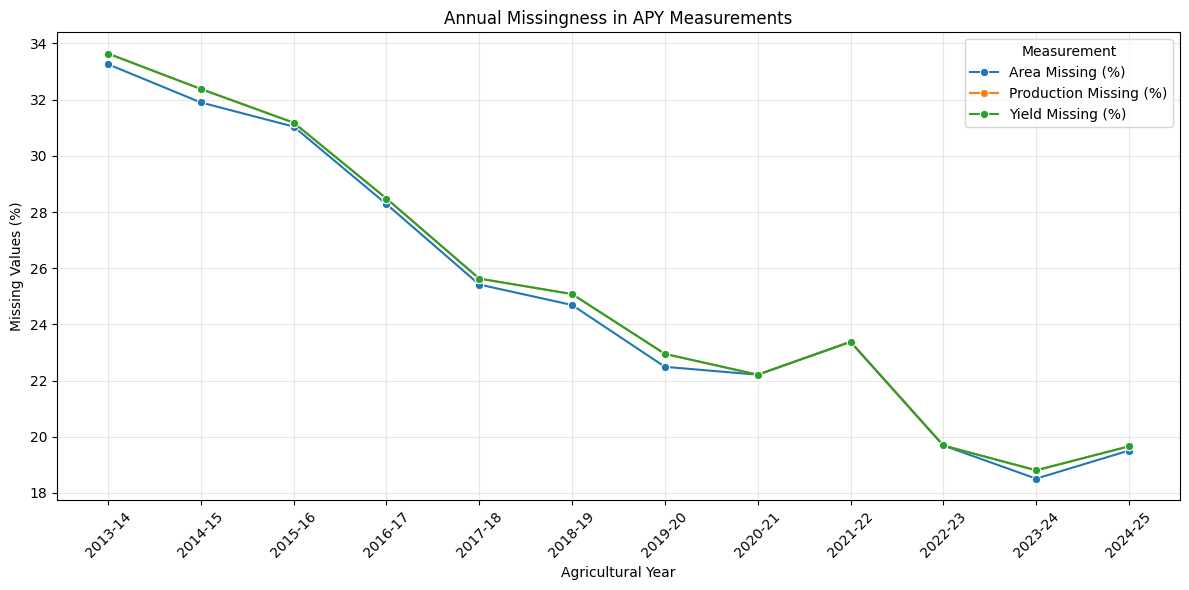

In [4]:
# Visualize annual missingness in Area, Production, and Yield.

missing_plot_df = missing_percent_by_year.reset_index()
missing_plot_df = missing_plot_df.rename(columns={"index": "Year"})

missing_plot_df = missing_plot_df.melt(
    id_vars="Year",
    var_name="Measurement",
    value_name="Missing Percentage"
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=missing_plot_df,
    x="Year",
    y="Missing Percentage",
    hue="Measurement",
    marker="o"
)

plt.title("Annual Missingness in APY Measurements")
plt.xlabel("Agricultural Year")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

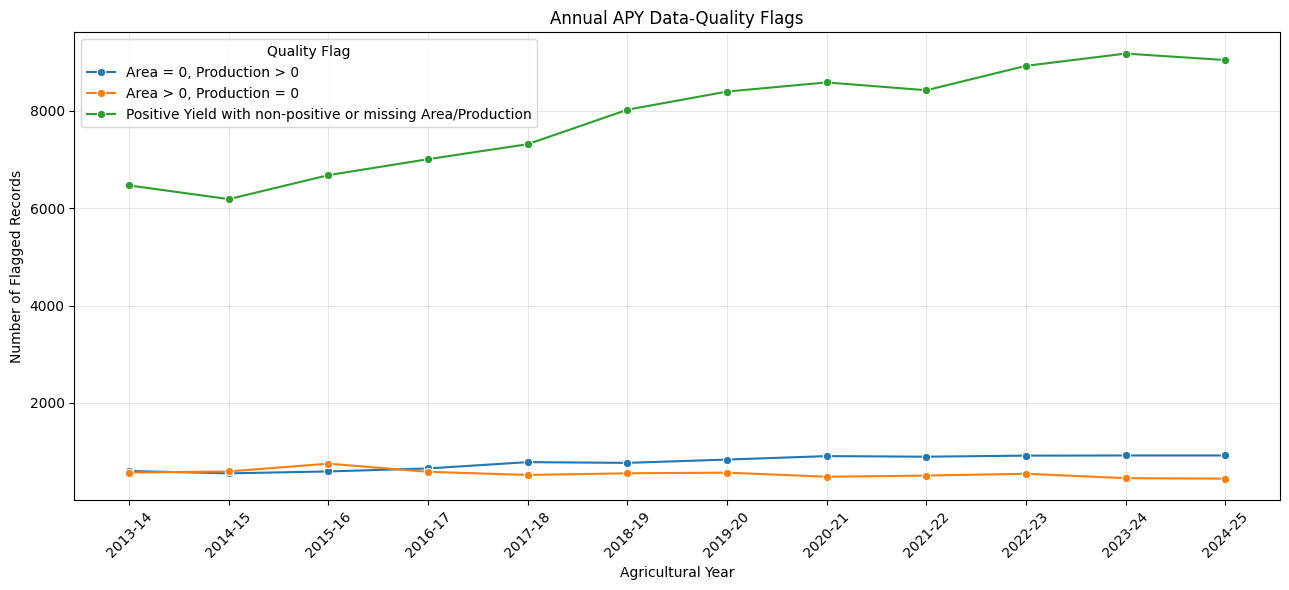

In [5]:
# Visualize annual counts of selected APY data-quality flags.

flag_plot_df = (
    quality_by_year[
        [
            "Area_Zero_Production_Positive",
            "Area_Positive_Production_Zero",
            "Positive_Yield_Inconsistent",
        ]
    ]
    .rename(columns={
        "Area_Zero_Production_Positive": "Area = 0, Production > 0",
        "Area_Positive_Production_Zero": "Area > 0, Production = 0",
        "Positive_Yield_Inconsistent": "Positive Yield with non-positive or missing Area/Production",
    })
    .reset_index()
    .melt(
        id_vars="Year",
        var_name="Quality Flag",
        value_name="Flagged Records",
    )
)

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=flag_plot_df,
    x="Year",
    y="Flagged Records",
    hue="Quality Flag",
    marker="o",
)

plt.title("Annual APY Data-Quality Flags")
plt.xlabel("Agricultural Year")
plt.ylabel("Number of Flagged Records")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# Examine crop and season coverage without mixing crop categories.

print("Crop classification:")
display(
    apy_eda_df[["Crop", "Crop_Category"]]
    .drop_duplicates()
    .sort_values(["Crop_Category", "Crop"])
    .reset_index(drop=True)
)

print("\nRecord counts by crop category:")
display(
    apy_eda_df.groupby("Crop_Category", observed=True)
    .size()
    .rename("Record Count")
    .to_frame()
)

# Count unique crop-season combinations by category.
crop_season_coverage = (
    apy_eda_df.groupby(
        ["Crop_Category", "Crop", "Season"],
        observed=True
    )
    .size()
    .rename("Record Count")
    .reset_index()
    .sort_values(["Crop_Category", "Crop", "Season"])
)

display(crop_season_coverage)

print("\nSeason record counts:")
display(
    apy_eda_df["Season"]
    .value_counts()
    .rename("Record Count")
    .to_frame()
)

Crop classification:


,Crop,Crop_Category
0,Total Food Grains,Aggregate Total — Exclude from Individual-Crop...
1,Total Pulses,Aggregate Total — Exclude from Individual-Crop...
2,Cereals,Grouping — Verify Source Definition
3,Nutri/Coarse Cereals,Grouping — Verify Source Definition
4,Other Pulses,Grouping — Verify Source Definition
5,Shree Anna /Nutri Cereals,Grouping — Verify Source Definition
6,Bajra,Individual Crop Candidate
7,Barley,Individual Crop Candidate
8,Gram,Individual Crop Candidate
9,Jowar,Individual Crop Candidate



Record counts by crop category:


,Record Count
Crop_Category,
Aggregate Total — Exclude from Individual-Crop Analysis,42072
Grouping — Verify Source Definition,107640
Individual Crop Candidate,226560


,Crop_Category,Crop,Season,Record Count
0,Aggregate Total — Exclude from Individual-Crop...,Total Food Grains,Kharif,8988
1,Aggregate Total — Exclude from Individual-Crop...,Total Food Grains,Rabi,8940
2,Aggregate Total — Exclude from Individual-Crop...,Total Food Grains,Summer,6168
3,Aggregate Total — Exclude from Individual-Crop...,Total Food Grains,Total,9012
4,Aggregate Total — Exclude from Individual-Crop...,Total Pulses,Total,8964
...,...,...,...,...
66,Individual Crop Candidate,Urad,Total,8028
67,Individual Crop Candidate,Wheat,Kharif,168
68,Individual Crop Candidate,Wheat,Rabi,7236
69,Individual Crop Candidate,Wheat,Summer,276



Season record counts:


,Record Count
Season,
Total,143028
Kharif,106692
Rabi,88704
Summer,37848


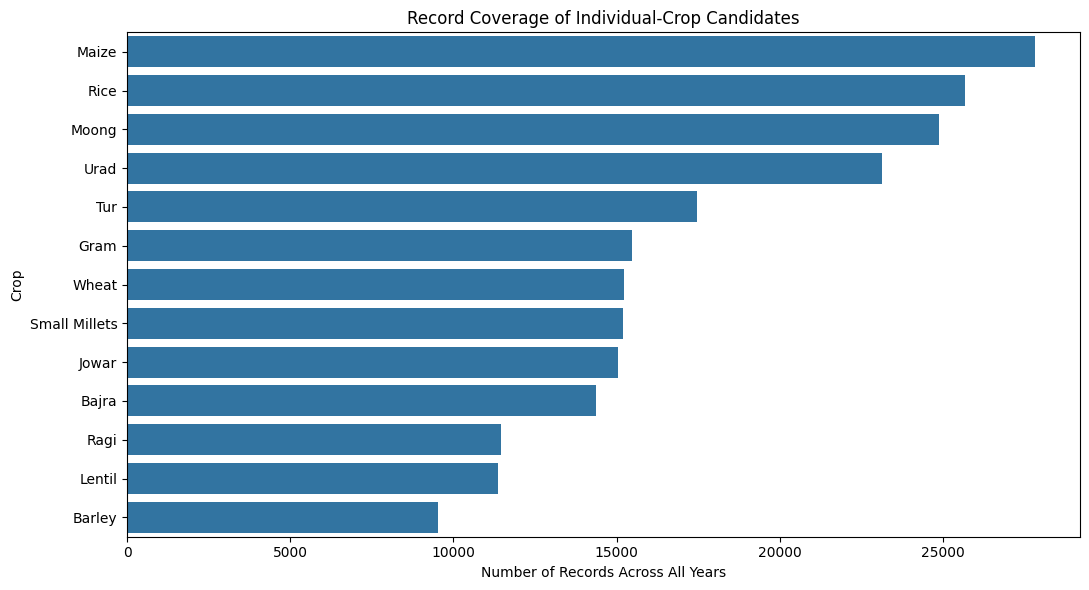

,Crop,Record Count
0,Maize,27804
1,Rice,25656
2,Moong,24888
3,Urad,23136
4,Tur,17448
5,Gram,15468
6,Wheat,15216
7,Small Millets,15204
8,Jowar,15036
9,Bajra,14376


In [7]:
# Compare record coverage for individual-crop candidates only.
# This measures representation in the dataset, not agricultural output.

individual_crop_df = apy_eda_df.loc[
    apy_eda_df["Crop_Category"] == "Individual Crop Candidate"
].copy()

crop_record_counts = (
    individual_crop_df.groupby("Crop", observed=True)
    .size()
    .sort_values(ascending=False)
    .reset_index(name="Record Count")
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=crop_record_counts,
    x="Record Count",
    y="Crop",
)

plt.title("Record Coverage of Individual-Crop Candidates")
plt.xlabel("Number of Records Across All Years")
plt.ylabel("Crop")
plt.tight_layout()
plt.show()

display(crop_record_counts)

In [8]:
# Prepare a separate dataset for individual-crop seasonal analysis.
# Exclude provisional groupings, aggregate totals, and Season = Total.

crop_trend_df = apy_eda_df.loc[
    (apy_eda_df["Crop_Category"] == "Individual Crop Candidate")
    & (apy_eda_df["Season"] != "Total")
].copy()

print("Original long-format dataset:", apy_eda_df.shape)
print("Crop trend dataset:", crop_trend_df.shape)

print("\nCrop categories included:")
display(crop_trend_df["Crop_Category"].value_counts().to_frame("Records"))

print("\nSeasons included:")
display(crop_trend_df["Season"].value_counts().to_frame("Records"))

print("\nCrops included:")
display(
    crop_trend_df["Crop"].value_counts().rename("Record Count").to_frame()
)

print("\nMissing measurements in trend dataset:")
display(crop_trend_df[["Area", "Production", "Yield"]].isna().sum().to_frame("Missing Count"))

Original long-format dataset: (376272, 13)
Crop trend dataset: (136464, 13)

Crop categories included:


,Records
Crop_Category,
Individual Crop Candidate,136464



Seasons included:


,Records
Season,
Kharif,65496
Rabi,50976
Summer,19992



Crops included:


,Record Count
Crop,
Maize,18984
Rice,17016
Moong,16608
Urad,15108
Tur,9468
Jowar,8988
Small Millets,8568
Bajra,8400
Gram,7896



Missing measurements in trend dataset:


,Missing Count
Area,44953
Production,45347
Yield,45347


In [9]:
# Calculate annual production summaries with explicit coverage information.
# Missing production values are excluded from the sum, not treated as zero.

annual_production = (
    crop_trend_df.groupby("Year", sort=True)
    .agg(
        Total_Records=("Production", "size"),
        Production_Observed=("Production", "count"),
        Production_Missing=("Production", lambda s: s.isna().sum()),
        Observed_Production_Sum=("Production", "sum"),
        Positive_Production_Records=("Production", lambda s: s.gt(0).sum()),
        Zero_Production_Records=("Production", lambda s: s.eq(0).sum()),
    )
    .reset_index()
)

annual_production["Production_Coverage_%"] = (
    annual_production["Production_Observed"]
    / annual_production["Total_Records"]
    * 100
).round(2)

display(annual_production)

,Year,Total_Records,Production_Observed,Production_Missing,Observed_Production_Sum,Positive_Production_Records,Zero_Production_Records,Production_Coverage_%
0,2013-14,11372,6662,4710,2729.72,4071,2591,58.58
1,2014-15,11372,6739,4633,2569.79,4217,2522,59.26
2,2015-16,11372,6876,4496,2478.29,4142,2734,60.46
3,2016-17,11372,7178,4194,3008.11,4346,2832,63.12
4,2017-18,11372,7547,3825,3075.52,4605,2942,66.36
5,2018-19,11372,7575,3797,3016.09,4377,3198,66.61
6,2019-20,11372,7934,3438,3414.29,4495,3439,69.77
7,2020-21,11372,8030,3342,3576.29,4542,3488,70.61
8,2021-22,11372,7856,3516,3432.71,4467,3389,69.08
9,2022-23,11372,8334,3038,3665.30,4638,3696,73.29


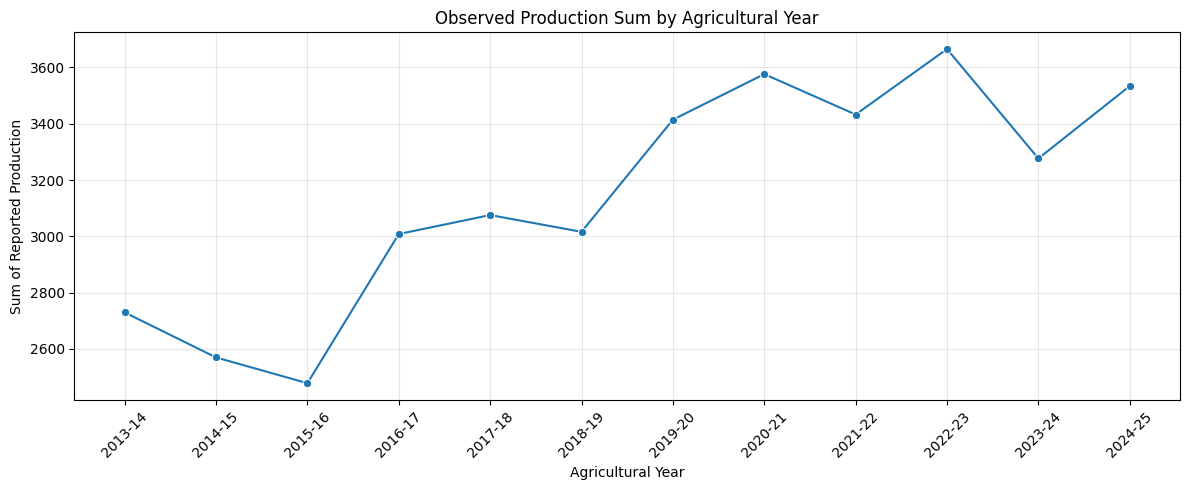

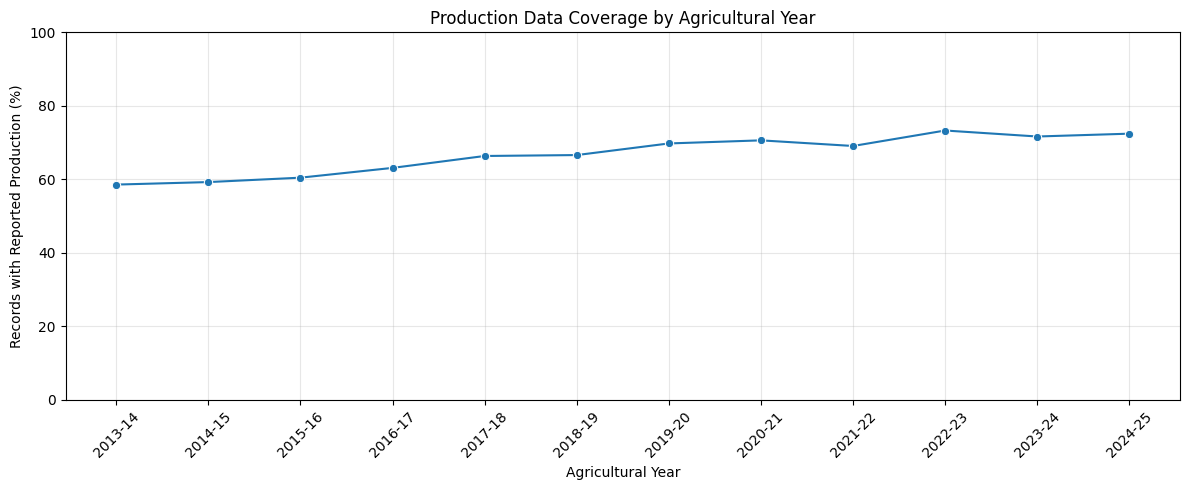

In [10]:
# Plot observed production sum by year.
# This is a partial sum of reported values, not a confirmed national total.

fig, ax = plt.subplots(figsize=(12, 5))

sns.lineplot(
    data=annual_production,
    x="Year",
    y="Observed_Production_Sum",
    marker="o",
    ax=ax,
)

ax.set_title("Observed Production Sum by Agricultural Year")
ax.set_xlabel("Agricultural Year")
ax.set_ylabel("Sum of Reported Production")
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Plot percentage of records with observed production.

fig, ax = plt.subplots(figsize=(12, 5))

sns.lineplot(
    data=annual_production,
    x="Year",
    y="Production_Coverage_%",
    marker="o",
    ax=ax,
)

ax.set_title("Production Data Coverage by Agricultural Year")
ax.set_xlabel("Agricultural Year")
ax.set_ylabel("Records with Reported Production (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
# Calculate annual observed production and coverage for each crop.

crop_annual_production = (
    crop_trend_df.groupby(["Year", "Crop"], sort=True)
    .agg(
        Total_Records=("Production", "size"),
        Production_Observed=("Production", "count"),
        Observed_Production_Sum=("Production", "sum"),
    )
    .reset_index()
)

crop_annual_production["Production_Coverage_%"] = (
    crop_annual_production["Production_Observed"]
    / crop_annual_production["Total_Records"]
    * 100
).round(2)

print("Annual crop summaries:", crop_annual_production.shape)
display(crop_annual_production.head(15))

Annual crop summaries: (156, 6)


,Year,Crop,Total_Records,Production_Observed,Observed_Production_Sum,Production_Coverage_%
0,2013-14,Bajra,700,343,99.17,49.00
1,2013-14,Barley,440,258,18.00,58.64
2,2013-14,Gram,658,442,76.18,67.17
3,2013-14,Jowar,749,430,62.39,57.41
4,2013-14,Lentil,479,321,9.46,67.01
5,2013-14,Maize,1582,969,262.04,61.25
6,2013-14,Moong,1384,740,16.77,53.47
7,2013-14,Ragi,560,254,20.46,45.36
8,2013-14,Rice,1418,948,1087.18,66.85
9,2013-14,Small Millets,714,293,3.82,41.04


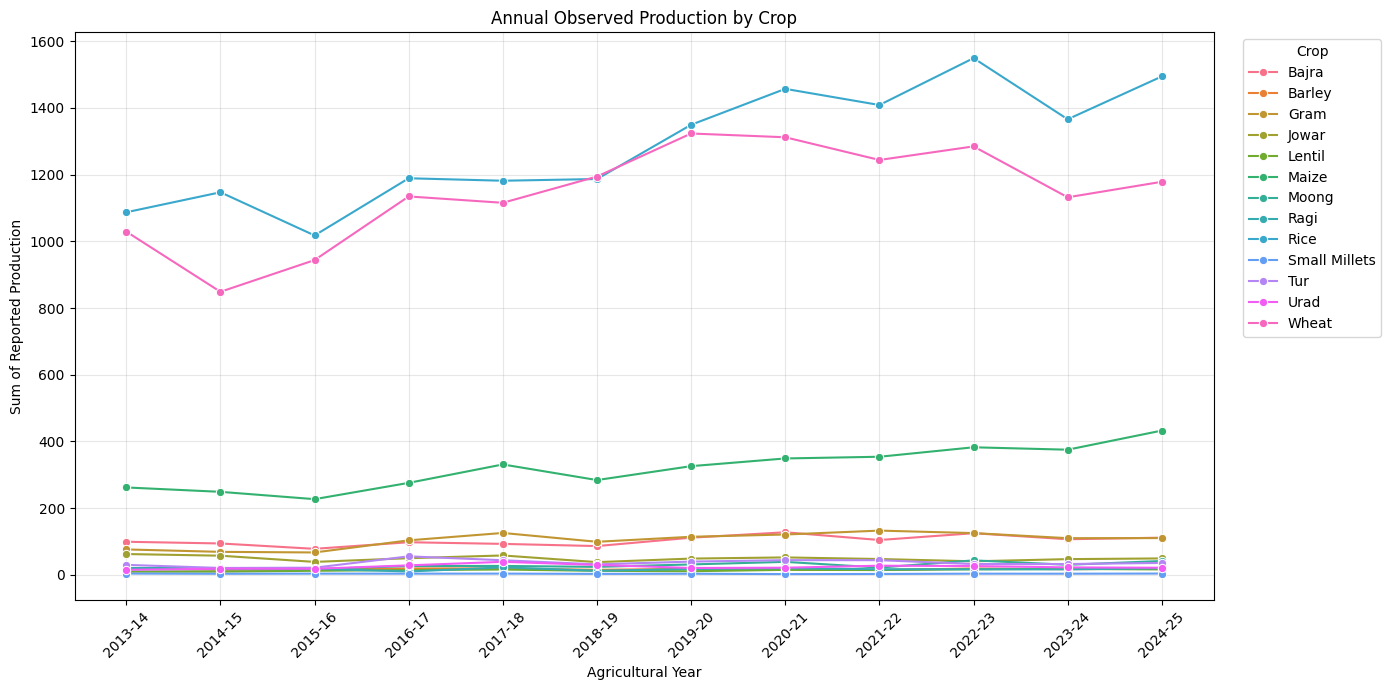

In [12]:
# Plot annual observed production separately for each crop.

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=crop_annual_production,
    x="Year",
    y="Observed_Production_Sum",
    hue="Crop",
    marker="o",
)

plt.title("Annual Observed Production by Crop")
plt.xlabel("Agricultural Year")
plt.ylabel("Sum of Reported Production")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.legend(title="Crop", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

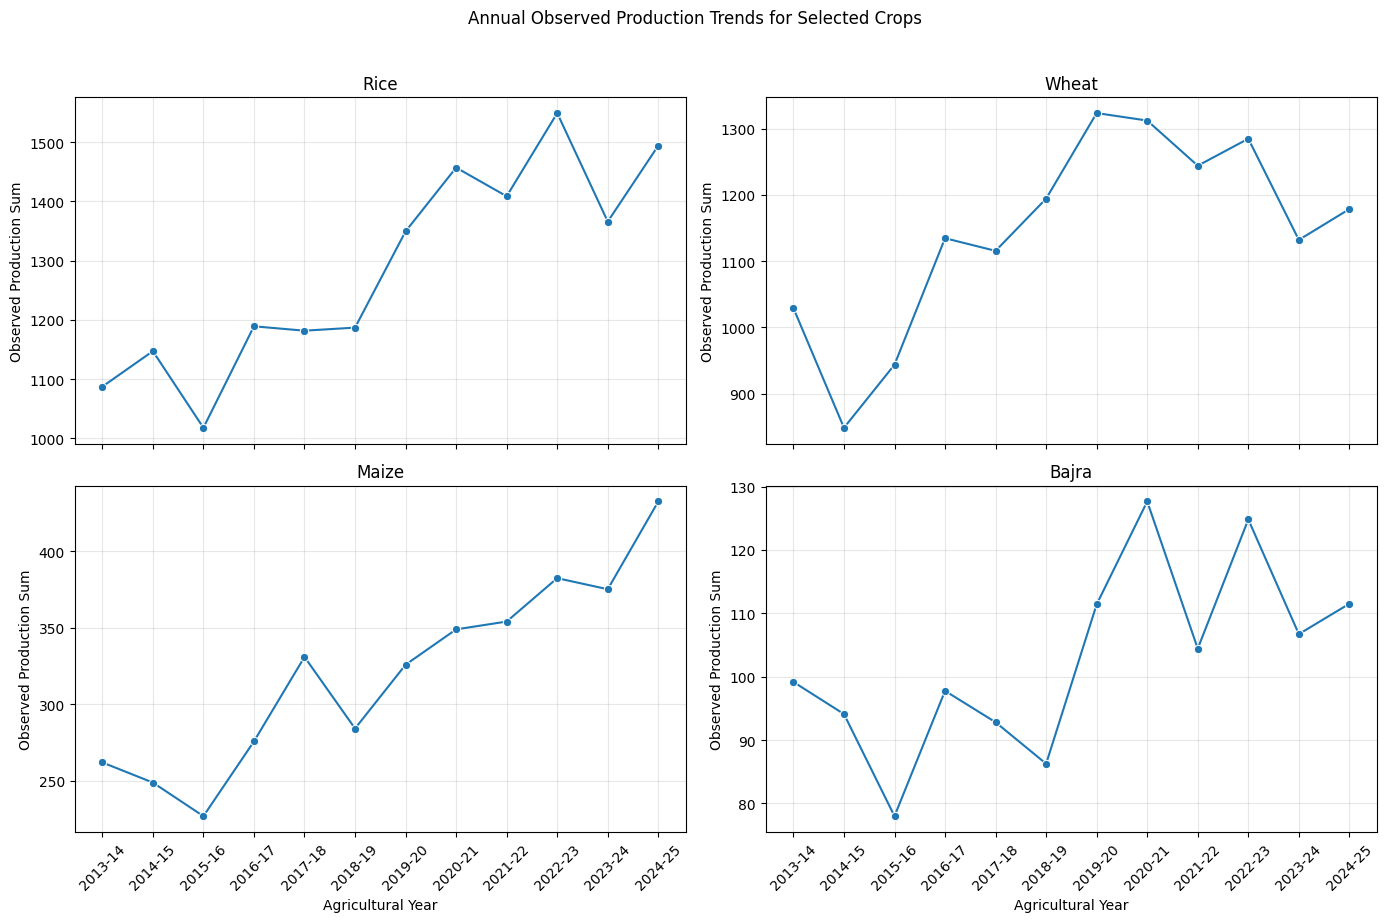

Crop,Bajra,Maize,Rice,Wheat
Year,,,,
2013-14,49.00,61.25,66.85,77.97
2014-15,49.57,63.53,68.34,78.28
2015-16,47.86,64.29,68.97,80.00
2016-17,49.86,67.19,73.55,80.94
2017-18,52.57,71.55,77.43,81.56
2018-19,56.86,67.83,76.30,82.50
2019-20,66.00,72.12,79.34,80.94
2020-21,65.00,72.69,81.66,83.44
2021-22,64.14,71.62,78.00,86.72


In [13]:
# Plot selected crop trends in separate panels for easier comparison.

selected_crops = ["Rice", "Wheat", "Maize", "Bajra"]

selected_crop_trends = crop_annual_production.loc[
    crop_annual_production["Crop"].isin(selected_crops)
].copy()

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(14, 9),
    sharex=True,
)

for crop, ax in zip(selected_crops, axes.flat):
    crop_data = selected_crop_trends.loc[
        selected_crop_trends["Crop"] == crop
    ]

    sns.lineplot(
        data=crop_data,
        x="Year",
        y="Observed_Production_Sum",
        marker="o",
        ax=ax,
    )

    ax.set_title(crop)
    ax.set_xlabel("Agricultural Year")
    ax.set_ylabel("Observed Production Sum")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)

fig.suptitle(
    "Annual Observed Production Trends for Selected Crops",
    y=1.02,
)
plt.tight_layout()
plt.show()

# Inspect the corresponding coverage values.
display(
    selected_crop_trends[
        ["Year", "Crop", "Observed_Production_Sum", "Production_Coverage_%"]
    ].pivot(
        index="Year",
        columns="Crop",
        values="Production_Coverage_%",
    ).round(2)
)

In [17]:
# Summarize Yield distributions by crop.
# Outliers are identified for investigation, not automatically removed.

yield_summary = (
    crop_trend_df.groupby("Crop", observed=True)["Yield"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99])
    .round(3)
)

display(yield_summary)

print("\nHighest observed Yield values:")
display(
    crop_trend_df.loc[
        crop_trend_df["Yield"].notna(),
        ["Year", "State", "District", "Crop", "Season",
         "Area", "Production", "Yield"]
    ]
    .nlargest(20, "Yield")
    .reset_index(drop=True)
)

,count,mean,std,min,25%,50%,75%,95%,99%,max
Crop,,,,,,,,,,
Bajra,4851.0,1581.307,836.509,0.0,1000.00,1393.0,2173.00,3021.00,3614.00,5541.0
Barley,3113.0,2307.891,1075.445,0.0,1420.00,2369.0,3179.00,4000.00,4448.92,5400.0
Gram,5923.0,1084.091,422.571,0.0,780.50,1036.0,1345.00,1841.00,2208.78,4031.0
Jowar,5754.0,1246.256,826.791,0.0,792.00,1083.0,1525.75,2422.70,4401.95,22000.0
Lentil,4126.0,854.827,419.632,0.0,642.25,833.0,1009.00,1400.00,1975.00,16880.0
Maize,13566.0,3077.097,1853.487,0.0,1850.00,2583.5,3714.00,7182.75,9213.80,17941.0
Moong,10625.0,633.118,1077.179,0.0,385.00,580.0,809.00,1167.80,1501.00,105588.0
Ragi,3469.0,1502.607,1099.025,0.0,800.00,1200.0,1796.00,3926.60,4500.00,21300.0
Rice,12926.0,2570.663,1083.924,0.0,1916.00,2551.0,3178.75,4187.00,4958.75,44815.0



Highest observed Yield values:


,Year,State,District,Crop,Season,Area,Production,Yield
0,2023-24,Andaman And Nicobar Islands,South Andamans,Urad,Rabi,0.00,0.00,385540.0
1,2023-24,Andaman And Nicobar Islands,South Andamans,Moong,Rabi,0.00,0.00,105588.0
2,2022-23,Goa,North Goa,Rice,Kharif,0.01,0.47,44815.0
3,2022-23,Goa,South Goa,Rice,Kharif,0.01,0.47,39221.0
4,2019-20,Telangana,Mulugu,Tur,Kharif,0.00,0.01,22846.0
5,2018-19,The Dadra And Nagar Haveli And Daman And Diu,Dadra And Nagar Haveli,Jowar,Kharif,0.00,0.00,22000.0
6,2020-21,Odisha,Nuapada,Ragi,Summer,0.00,0.00,21300.0
7,2022-23,Chhattisgarh,Khairagarh-Chhuikhadan-Gandai,Maize,Kharif,0.00,0.03,17941.0
8,2022-23,Chhattisgarh,Khairagarh-Chhuikhadan-Gandai,Lentil,Rabi,0.01,0.22,16880.0
9,2020-21,Himachal Pradesh,Hamirpur,Rice,Kharif,0.01,0.13,15726.0


## Key EDA Findings

### 1. Data Coverage
- The long-format APY dataset contains 376,272 records covering 12 agricultural years (2013–14 to 2024–25).
- Production data coverage improved from approximately 58.6% in 2013–14 to 72.4% in 2024–25.
- Missing measurements remain significant, so observed production totals should not be interpreted as complete national or regional totals.

### 2. Crop Production Trends
- Rice and wheat have comparatively high observed production sums among the selected crops.
- Observed production generally increased for rice and maize over the study period, although individual years show fluctuations.
- These trends describe reported observations; changing data coverage may contribute to apparent changes.

### 3. Data Quality
- Some records contain zero area or production alongside positive yield.
- Several crops contain unusually large yield values, including extreme values for Urad, Moong, Rice, and other crops.
- These observations require validation against source definitions and reporting conventions before removal or correction.

### 4. Crop Classification
- The dataset distinguishes individual-crop candidates from aggregate totals and crop groupings requiring verification.
- Aggregate totals must be excluded from individual-crop comparisons to avoid double-counting.
- Crop-group classifications remain provisional until verified against the original source documentation.

### 5. Limitations
- Measurement units and yield definitions have not yet been independently validated.
- Missing values have not been imputed, and suspicious observations have not been deleted.
- Production comparisons are based on observed values and should be interpreted alongside data-coverage statistics.

### Conclusion
The APY dataset is ready for further visualization and carefully controlled feature engineering. Before building predictive models, validate measurement definitions, investigate suspicious yield observations, and define rules for missing data and crop selection.